# ATSA Presentation 
# <span style="color:blue;">Roll No D-003 & D013
# <span style="color:brown;">Pradeep Talwelkar & Vishal Shah
# Date:- 13th October 2024

# <span style="color:Crimson;">Univariate Models

### <span style="color:crimson;"> Micro Gas Turbine Electrical Energy Prediction Dataset from UC Irvine Machine Learning Repository

The dataset consists of three columns:

time: The time values.
    
input_voltage: A constant value (10) in this case.
    
el_power: The electric power measurements, which is the time series of interest for ARMA modeling.

### <span style="color:Red;"> https://archive.ics.uci.edu/dataset/994/micro+gas+turbine+electrical+energy+prediction



# <span style="color:Purple;">1. MA Model

The code is designed to load a ex_1.csv dataset, visualize it, and fit a Moving Average (MA) model using the ARIMA framework from statsmodels. It then provides a forecast for a few steps ahead. 

<span style="color:green;"> __Importing necessary libraries:__

pandas for handling the dataset.
statsmodels.api for statistical modeling, especially for time series.
matplotlib.pyplot for plotting and visualizing the data.

<span style="color:green;"> __Dataset Loading:__

The dataset ex_1.csv is in the current directory.
Convert the 'time' column from seconds (assuming UNIX timestamp) to a datetime format and sets it as the index of the DataFrame.

<span style="color:green;"> __Plotting:__

Plots the column el_power (which represents electrical power) over time.

<span style="color:green;"> __Fitting the MA model:__

The ARIMA model with parameters (0, 0, q) represents an MA model because the ARIMA model (p, d, q) fits autoregressive (AR), integrated (I), and moving average (MA) components.
q=3 is specified, which means a moving average model with 3 lagged terms.

<span style="color:green;"> __Summary:__

Outputs the summary of the model fit, which provides statistical details.

<span style="color:green;"> __Forecasting:__

Uses the forecast method to predict the next 10 time steps.


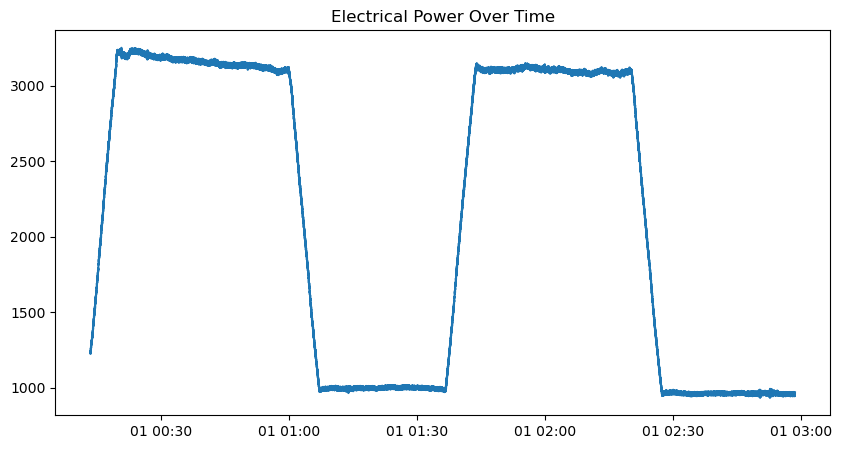

C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:               el_power   No. Observations:                 9920
Model:                 ARIMA(0, 0, 3)   Log Likelihood              -71145.955
Date:                Sat, 05 Oct 2024   AIC                         142301.911
Time:                        15:25:48   BIC                         142337.923
Sample:                             0   HQIC                        142314.106
                               - 9920                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2162.4179     19.001    113.804      0.000    2125.176    2199.660
ma.L1          1.9541      0.010    191.345      0.000       1.934       1.974
ma.L2          1.9532      0.028     70.636      0.0

C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:834: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


In [1]:
# Required libraries
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv('ex_1.csv')

# Setting the time column as index
data['time'] = pd.to_datetime(data['time'], unit='s')  # Assuming the 'time' column is in seconds
data.set_index('time', inplace=True)

# Visualize the data
plt.figure(figsize=(10, 5))
plt.plot(data['el_power'])
plt.title('Electrical Power Over Time')
plt.show()

# Fitting an MA model
# Note: q is the window size for the moving average
q = 3  # You can adjust the number of lags
model = sm.tsa.ARIMA(data['el_power'], order=(0, 0, q))  # (p=0, d=0, q=MA order)
results = model.fit()

# Summary of the model
print(results.summary())

# Forecasting the next few steps
forecast_steps = 10
forecast = results.forecast(steps=forecast_steps)

# Since the forecast is likely a NumPy array, we can print it directly
print(f"Forecasted values: {forecast}")


# Comparison Parameters
from sklearn.metrics import mean_squared_error
import numpy as np

# AIC and BIC from the model results
aic = results.aic
bic = results.bic

# Calculate Root Mean Squared Error (RMSE)
# Getting the model residuals (errors)
residuals = results.resid

# Compute RMSE from residuals
rmse = np.sqrt(mean_squared_error(data['el_power'], results.fittedvalues))

# Printing the comparison metrics
print(f"AIC: {aic}")
print(f"BIC: {bic}")
print(f"RMSE: {rmse}")

# Mean Absolute Error (MAE)
mae = np.mean(np.abs(residuals))
print(f"MAE: {mae}")

# Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs(residuals / data['el_power'])) * 100
print(f"MAPE: {mape}%")












## <span style="color:orange;"> For MA Model 
    
<span style="color:orange;">**AIC: 142301.91097456167**
    
<span style="color:orange;">**BIC: 142337.92251556306**
    
<span style="color:orange;">**RMSE: 315.06586975351**
    
<span style="color:orange;">**MAE: 251.079159122662**
    
<span style="color:orange;">**MAPE: 16.7205431178981 %**

# <span style="color:Purple;"> 2. AR Model

This code performs a time series analysis and forecasting using the ARIMA (Autoregressive Integrated Moving Average) (1, 0, 0) model or AR(1) Model

<span style="color:green;"> __AR (Autoregressive) part:__

The "1" in ARIMA(1, 0, 0) indicates that the model uses one lag of the dependent variable (the time series) to predict its current value. This means that the current value of the series is regressed on its immediately preceding value.

<span style="color:green;"> __I (Integrated) part:__

The "0" indicates that no differencing of the time series is applied. Differencing is typically used to make a non-stationary series stationary.

<span style="color:green;"> __MA (Moving Average) part:__

The "0" means that no lagged forecast errors are included in the model. So, it only relies on the past values of the series itself for predictions.


<span style="color:green;"> __Characteristics of the AR Model__
The AR model captures the relationship between an observation and a number of lagged observations (previous values).

For an AR(1) model, the equation can be represented as:

𝑋𝑡 = 𝑐 + 𝜙1𝑋𝑡−1 + 𝜖𝑡

where:
    
𝑋𝑡  is the current value of the series,
    
𝑐 is a constant,
    
𝜙1 is the coefficient for the lagged term,
    
𝑋𝑡−1 is the previous value of the series,
    
𝜖𝑡 is the white noise error term.


<span style="color:green;"> __1. Importing Libraries__
    
The necessary libraries for data manipulation (pandas, numpy), visualization (matplotlib), and time series analysis (statsmodels) are imported.

<span style="color:green;"> __2. Loading the Dataset__
    
The dataset is loaded from a CSV file named ex_1.csv. You should ensure this file is in the same directory or provide the correct path.

<span style="color:green;"> __3. Plotting the Raw Data__
    
The first visualization shows the electrical power consumption over time, helping you to identify any trends or seasonal patterns.

<span style="color:green;"> __4. ADF Test for Stationarity__
    
The Augmented Dickey-Fuller (ADF) test checks whether the time series is stationary. The ADF statistic, p-value, and critical values are printed. A low p-value (typically less than 0.05) indicates that the time series is stationary.

<span style="color:green;"> __5. ACF and PACF Plots__
    
The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots help determine the appropriate values for the AR (p) and MA (q) components of the ARIMA model. ACF shows the correlation of the series with its own lagged values.
PACF shows the correlation of the series with its own lagged values after removing the effects of shorter lags.

<span style="color:green;"> __6. Fitting the AR(1) Model__
    
An ARIMA(1, 0, 0) model (which is essentially an AR(1) model) is fitted to the series. The summary of the model provides insights into the coefficients and their significance.

<span style="color:green;"> __7. Residual Analysis__
The residuals of the fitted model are plotted to check 
    for randomness (ideally, they should resemble white noise). ACF and PACF plots of the residuals are also generated to check for any remaining autocorrelation.

<span style="color:green;"> __8. Ljung-Box Test__
    
The Ljung-Box test checks if there are significant autocorrelations in the residuals. If the p-value is high, it suggests that there is no autocorrelation in the residuals, supporting the adequacy of the model.

<span style="color:green;"> __9. Forecasting__
The next 10 points of the time series are forecasted using the fitted AR(1) model. The forecast and its confidence intervals are plotted against the observed data.

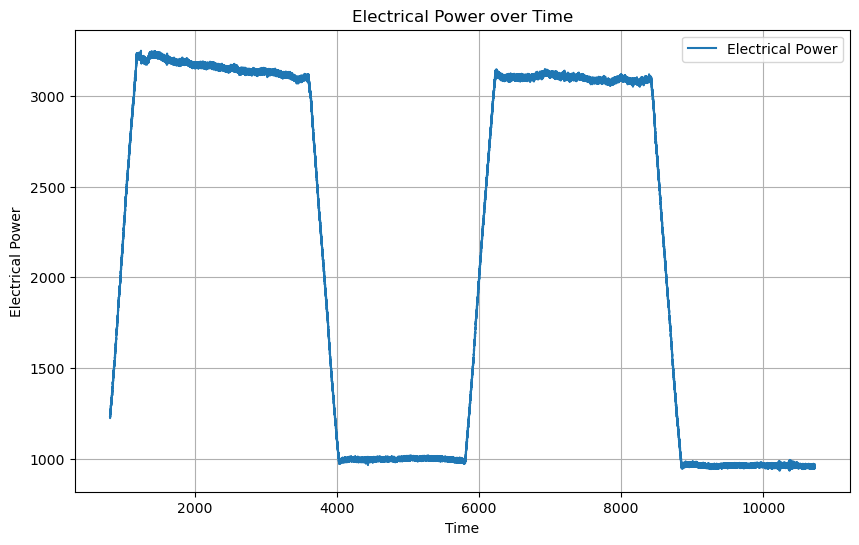

ADF Statistic: -2.88003477482922
p-value: 0.04771942827842128
Critical Values:
   1%: -3.4310119774951406
   5%: -2.861832554286939
   10%: -2.566925721514317


<Figure size 1000x500 with 0 Axes>

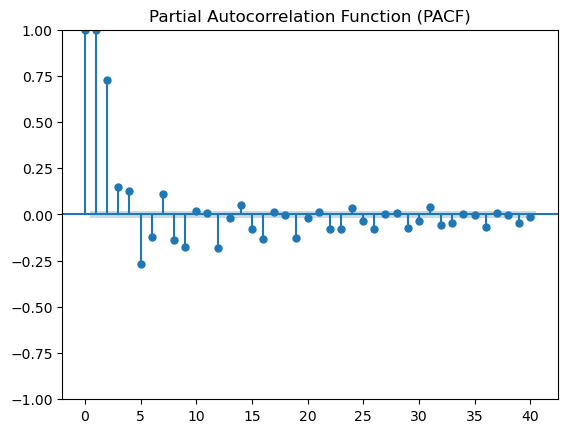

<Figure size 1000x500 with 0 Axes>

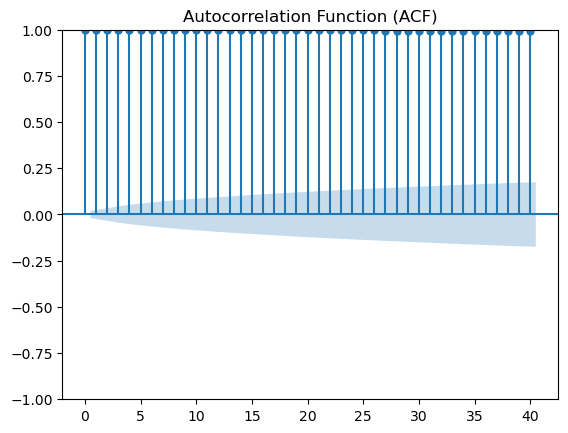

                               SARIMAX Results                                
Dep. Variable:               el_power   No. Observations:                 9920
Model:                 ARIMA(1, 0, 0)   Log Likelihood              -43787.749
Date:                Sat, 05 Oct 2024   AIC                          87581.499
Time:                        15:25:50   BIC                          87603.106
Sample:                             0   HQIC                         87588.816
                               - 9920                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2162.4279    906.568      2.385      0.017     385.587    3939.268
ar.L1          0.9998      0.000   4758.680      0.000       0.999       1.000
sigma2       399.2225     11.180     35.709      0.0

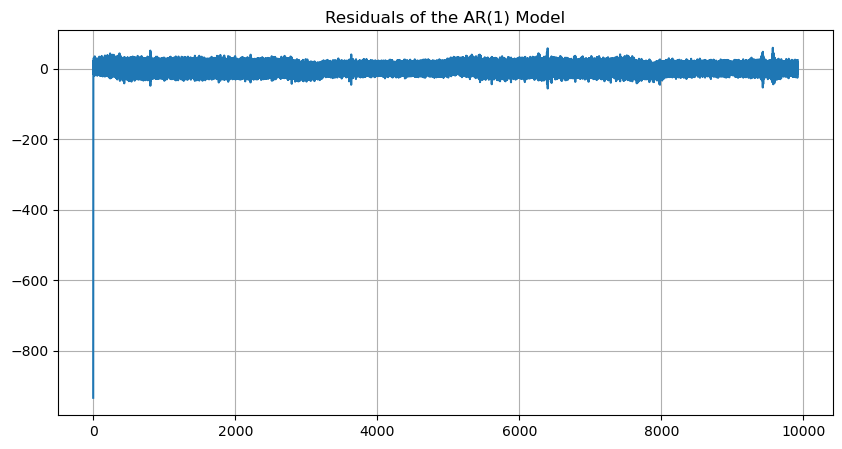

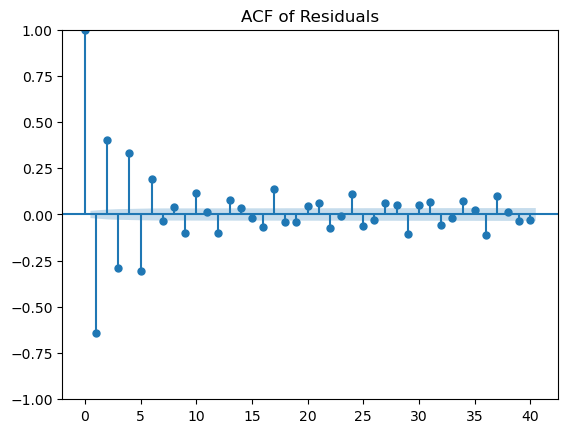

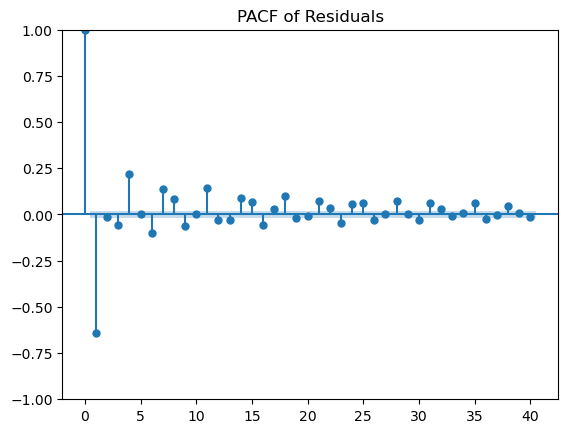

Ljung-Box Test Results:
        lb_stat  lb_pvalue
10  9216.223299        0.0


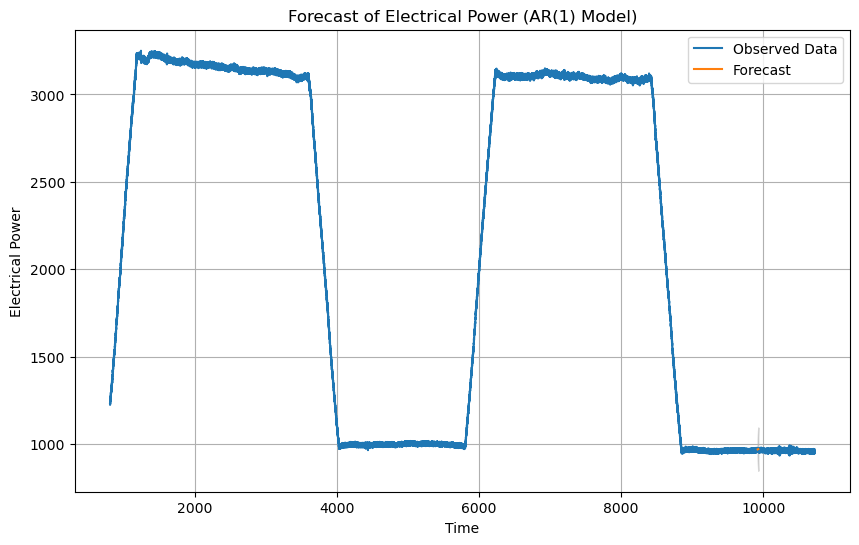

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import warnings
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Extract the relevant time series (el_power column)
el_power_series = data['el_power']

# Step 1: Plot the raw data to visualize the time series
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Step 2: Perform the ADF test to check stationarity
adf_test = adfuller(el_power_series)

print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}")
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value}")

# Step 3: Plot ACF and PACF to identify AR and MA terms
plt.figure(figsize=(10, 5))
plot_pacf(el_power_series, lags=40)
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()

plt.figure(figsize=(10, 5))
plot_acf(el_power_series, lags=40)
plt.title('Autocorrelation Function (ACF)')
plt.show()

# Step 4: ARIMA model for AR(1)
# ARIMA(1, 0, 0) represents AR(1) with no differencing (d=0) and no moving average terms (q=0)

p, d, q = 1, 0, 0

# Fit AR(1) model
model = ARIMA(el_power_series, order=(p, d, q))
model_fit = model.fit()

# Step 5: Summary of the ARIMA model
print(model_fit.summary())

# AIC and BIC
aic = model_fit.aic
bic = model_fit.bic

print(f"AIC: {aic}")
print(f"BIC: {bic}")

# Step 6: Calculate RMSE, MAE, MAPE for model
# Get predicted values for in-sample (fitted) data
fitted_values = model_fit.fittedvalues

# RMSE
rmse = np.sqrt(mean_squared_error(el_power_series, fitted_values))
print(f"RMSE: {rmse}")

# MAE
mae = mean_absolute_error(el_power_series, fitted_values)
print(f"MAE: {mae}")

# MAPE (Mean Absolute Percentage Error)
mape = np.mean(np.abs((el_power_series - fitted_values) / el_power_series)) * 100
print(f"MAPE: {mape}")

# Step 7: Plot the residuals to check for randomness
plt.figure(figsize=(10, 5))
plt.plot(model_fit.resid)
plt.title('Residuals of the AR(1) Model')
plt.grid(True)
plt.show()

# Plot ACF and PACF of residuals to check for autocorrelation
plot_acf(model_fit.resid, lags=40)
plt.title('ACF of Residuals')
plt.show()

plot_pacf(model_fit.resid, lags=40)
plt.title('PACF of Residuals')
plt.show()

# Step 8: Ljung-Box test for residual autocorrelation
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(model_fit.resid, lags=[10], return_df=True)
print("Ljung-Box Test Results:")
print(lb_test)

# Step 9: Forecasting the next 10 points using the fitted AR(1) model
forecast = model_fit.get_forecast(steps=10)
forecast_ci = forecast.conf_int()

# Plot the forecasted values
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Observed Data')
plt.plot(np.arange(len(data), len(data) + 10), forecast.predicted_mean, label='Forecast')
plt.fill_between(np.arange(len(data), len(data) + 10),
                 forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='gray', alpha=0.3)
plt.title('Forecast of Electrical Power (AR(1) Model)')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()



## <span style="color:orange;"> For AR Model 
    
<span style="color:orange;">**AIC: 87581.4989274149**
    
<span style="color:orange;">**BIC: 87603.10585201574**
    
<span style="color:orange;">**RMSE: 22.069273924782024**
    
<span style="color:orange;">**MAE: 18.65331198633499**
    
<span style="color:orange;">**MAPE: 1.0641399794449966 %**

# <span style="color:Purple;"> 3. AUTOREGRESSIVE MOVING AVERAGE (ARMA) MODEL

This code performs a time series analysis and forecasting using the ARIMA model, specifically an ARIMA(2, 0, 2) model.

<span style="color:green;"> __AR: Autoregressive part, represented by the parameter 𝑝.__

𝑝=2 means that the model uses 2 lagged values of the time series.

<span style="color:green;"> __I: Integrated part, represented by the parameter 𝑑.__

𝑑=0 indicates that no differencing is applied, which means the series is assumed to be stationary._

**This effectively makes the model an ARMA model because there is no differencing involved.**

<span style="color:green;"> __MA: Moving Average part, represented by the parameter 𝑞.__

𝑞=2 means the model uses 2 lagged forecast errors.

Since the model is defined with 𝑑=0, it is an ARMA(2, 2) model, which is a special case of the ARIMA model. 

ARIMA can be thought of as a generalization of ARMA, allowing for non-stationary time series through differencing when 𝑑>0.


<span style="color:green;">__1. Importing Libraries__
    
We import necessary libraries for data manipulation (pandas, numpy), plotting (matplotlib.pyplot), and statistical modeling (statsmodels). The warning filter is applied to suppress warnings that may arise during the execution of your code.

<span style="color:green;"> __2. Data Loading__
    
We load the dataset and extract the el_power column for analysis. 

<span style="color:green;"> __3. Visualization__
    
We visualize the time series data and generate the Partial Autocorrelation Function (PACF) and Autocorrelation Function (ACF) plots. This helps in understanding the temporal structure of the data.

<span style="color:green;"> __4. ARIMA Model Fitting__
    
We define the ARIMA model with parameters 𝑝=2, 𝑑=0, and 𝑞=2, and fit the model to the el_power data. We print the summary of the fitted model, which provides useful diagnostics.

<span style="color:green;"> __5. Residual Analysis__
    
We plot the residuals to check if they behave like white noise. Then we plot the ACF and PACF of the residuals to ensure no significant autocorrelation remains. This is crucial for validating the model.

<span style="color:green;"> __6. Ljung-Box Test__
    
We apply the Ljung-Box test to statistically confirm the absence of autocorrelation in the residuals, which is important for the validity of our ARIMA model.

<span style="color:green;"> __7. Forecasting__
    
We forecast the next 10 time points and visualize both the observed and forecasted data. The confidence intervals are also plotted to provide insight into the uncertainty of the forecasts.


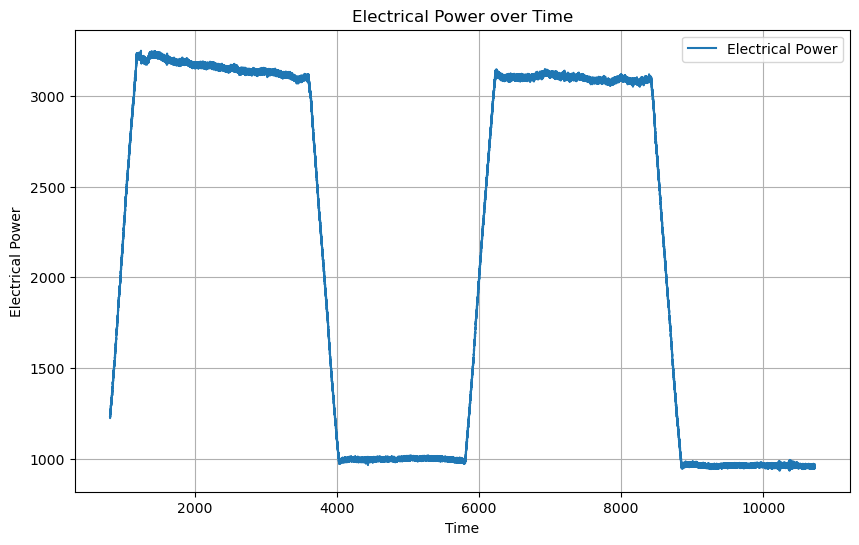

<Figure size 1000x500 with 0 Axes>

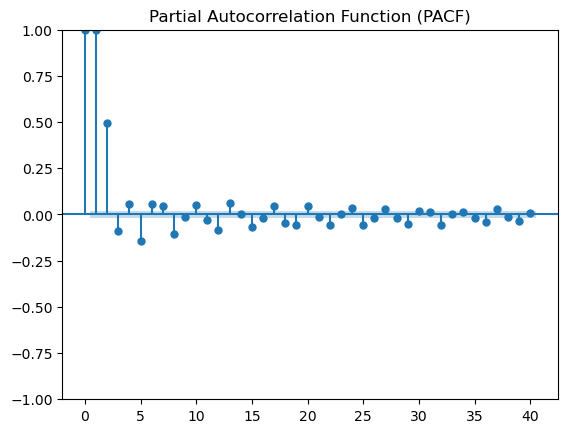

<Figure size 1000x500 with 0 Axes>

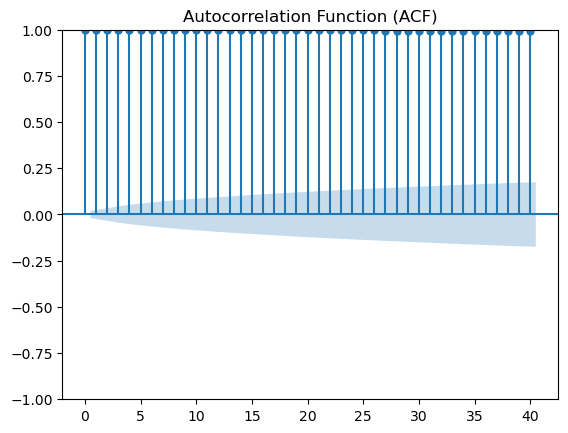

                               SARIMAX Results                                
Dep. Variable:               el_power   No. Observations:                 9920
Model:                 ARIMA(2, 0, 2)   Log Likelihood              -37774.344
Date:                Sat, 05 Oct 2024   AIC                          75560.689
Time:                        15:26:09   BIC                          75603.903
Sample:                             0   HQIC                         75575.322
                               - 9920                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2162.3684    474.199      4.560      0.000    1232.956    3091.781
ar.L1          0.7264      0.016     45.961      0.000       0.695       0.757
ar.L2          0.2735      0.016     17.306      0.0

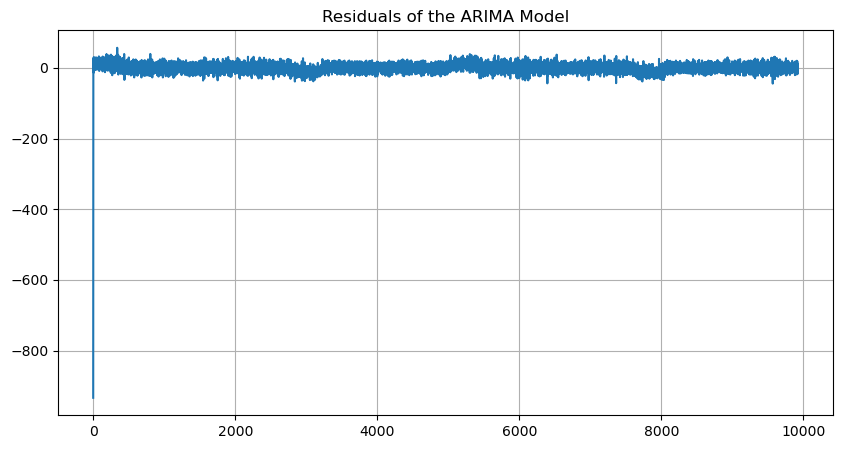

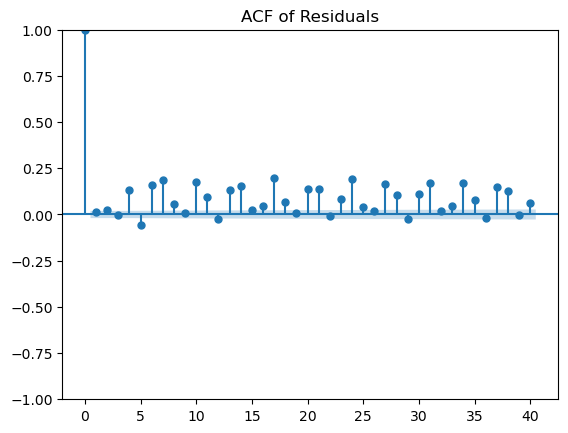

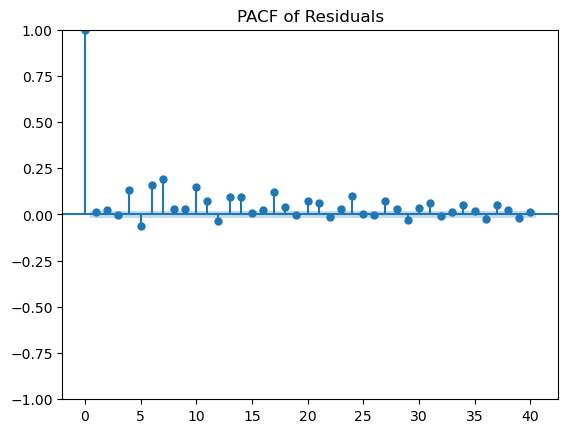

Ljung-Box Test Results:
        lb_stat      lb_pvalue
10  1144.858846  1.124027e-239


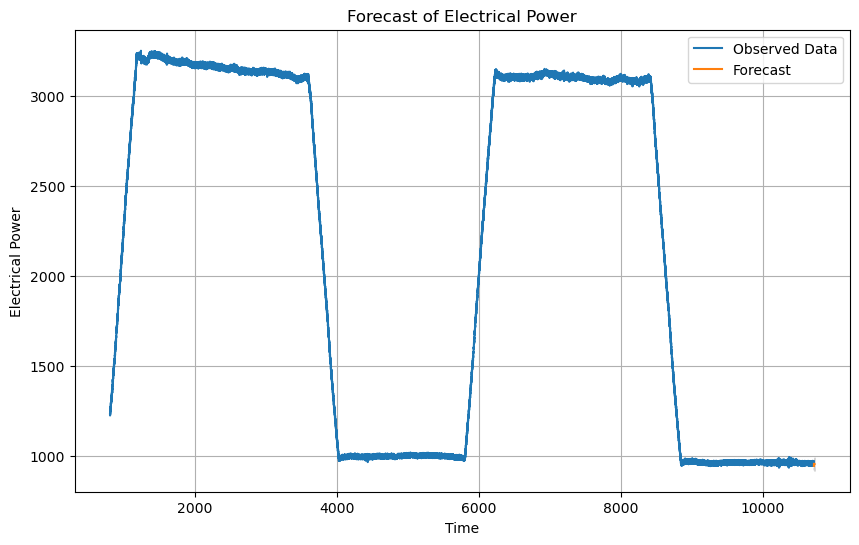

AIC: 75560.6889696246
BIC: 75603.90281882627
RMSE: 9.533227610716276
MAE: 8.435868927015713
MAPE: 0.8798867618262285%


In [3]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings

warnings.filterwarnings('ignore')

# Data Loading:

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Visualization:

# Plot the raw data
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Simulating PACF and ACF plots
plt.figure(figsize=(10, 5))
plot_pacf(data['el_power'], lags=40, method='ywm')
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()

plt.figure(figsize=(10, 5))
plot_acf(data['el_power'], lags=40)
plt.title('Autocorrelation Function (ACF)')
plt.show()

# ARIMA Model:

# Fit ARMA/ARIMA model to the el_power time series data
p, d, q = 2, 0, 2  # ARIMA(2, 0, 2) model

model = ARIMA(data['el_power'], order=(p, d, q))
model_fit = model.fit()

# Summary of the model
print(model_fit.summary())

# Residual Analysis:

# Plot the residuals
plt.figure(figsize=(10, 5))
plt.plot(model_fit.resid)
plt.title('Residuals of the ARIMA Model')
plt.grid(True)
plt.show()

# Plot ACF and PACF of residuals
plot_acf(model_fit.resid, lags=40)
plt.title('ACF of Residuals')
plt.show()

plot_pacf(model_fit.resid, lags=40, method='ywm')
plt.title('PACF of Residuals')
plt.show()

# Ljung-Box Test:

lb_test = acorr_ljungbox(model_fit.resid, lags=[10], return_df=True)
print("Ljung-Box Test Results:")
print(lb_test)

# Forecasting:

forecast = model_fit.get_forecast(steps=10)
forecast_ci = forecast.conf_int()

# Plot the forecasted values
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Observed Data')
plt.plot(np.arange(data['time'].iloc[-1], data['time'].iloc[-1] + 10), forecast.predicted_mean, label='Forecast')
plt.fill_between(np.arange(data['time'].iloc[-1], data['time'].iloc[-1] + 10),
                 forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='gray', alpha=0.3)
plt.title('Forecast of Electrical Power')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()

# Calculating AIC and BIC
aic = model_fit.aic
bic = model_fit.bic
print(f"AIC: {aic}")
print(f"BIC: {bic}")

# Calculating RMSE, MAE, and MAPE
# Forecasting using the last known values for comparison
actual = data['el_power'].values[-10:]  # last 10 observed values
predicted = forecast.predicted_mean.values  # forecasted values

# Calculate RMSE
rmse = np.sqrt(np.mean((actual - predicted) ** 2))
print(f"RMSE: {rmse}")

# Calculate MAE
mae = np.mean(np.abs(actual - predicted))
print(f"MAE: {mae}")

# Calculate MAPE
mape = np.mean(np.abs((actual - predicted) / actual)) * 100
print(f"MAPE: {mape}%")




## <span style="color:orange;"> For ARMA Model 
    
<span style="color:orange;">**AIC: 75560.6889696246**
    
<span style="color:orange;">**BIC: 75603.90281882627**
    
<span style="color:orange;">**RMSE: 9.533227610716276**
    
<span style="color:orange;">**MAE: 8.435868927015713**
    
<span style="color:orange;">**MAPE: 0.8798867618262285 %**

# <span style="color:Purple;"> 4. AUTOREGRESSIVE INTEGRATED MOVING AVERAGE (ARIMA) MODEL

To modify the code for ARIMA (Autoregressive Integrated Moving Average) instead of ARMA, we need to introduce differencing, which is the "I" component in ARIMA. 

The order of differencing is controlled by the d parameter in ARIMA(p, d, q), where:

p: Number of autoregressive terms.

d: Number of differences needed to make the series stationary.

q: Number of moving average terms.

Choosing the right parameters (𝑝,𝑑,𝑞) for an ARIMA model is crucial for obtaining a good fit and accurate forecasts. 

<span style="color:green;"> __1. Determine 𝑑 (Differencing Order):__
    
Stationarity Check: The first step is to determine if the time series is stationary. We can perform the Augmented Dickey-Fuller (ADF) test in the code.
If the p-value is greater than 0.05, the series is non-stationary, and we should use differencing:
𝑑=1 if the series requires first differencing.
You can also apply seasonal differencing if you observe seasonal patterns.
If the series is stationary (p-value ≤ 0.05), then 
𝑑=0.

<span style="color:green;"> __2. Determine 𝑝 (Autoregressive Order):__
    
PACF Plot: Use the Partial Autocorrelation Function (PACF) plot to identify the order of the autoregressive (AR) component.
Look for the lag at which the PACF plot cuts off. The point at which the PACF drops to zero (or becomes negligible) indicates the potential value for 𝑝.

<span style="color:green;"> __3. Determine 𝑞 (Moving Average Order):__
    
ACF Plot: Use the Autocorrelation Function (ACF) plot to identify the order of the moving average (MA) component.
Similar to PACF, look for the lag where the ACF cuts off. The lag at which the ACF drops to zero indicates the potential value for 𝑞.

<span style="color:green;"> __4. Using Information Criteria:__
    
Consider using AIC (Akaike Information Criterion) or BIC (Bayesian Information Criterion) for model selection. Lower values of AIC/BIC indicate a better model fit.



<span style="color:green;"> __Importing Libraries:__
    
Essential libraries such as pandas, numpy, matplotlib, and statsmodels are imported for data manipulation, visualization, and time series analysis.

<span style="color:green;"> __Loading the Dataset:__

The dataset is loaded from a CSV file into a Pandas DataFrame. You extract the el_power column as the time series to be analyzed.

<span style="color:green;"> __Visualizing the Time Series:__
    
You plot the raw electrical power data over time to visually inspect trends and patterns.

<span style="color:green;"> __Stationarity Check with ADF Test:__
    
The Augmented Dickey-Fuller (ADF) test is performed to check the stationarity of the time series. If the p-value is greater than 0.05, the series is deemed non-stationary.

<span style="color:green;"> __ACF and PACF Plots:__
    
You plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) to identify potential values for the autoregressive (AR) and moving average (MA) components of the ARIMA model.

<span style="color:green;"> __Differencing:__
 
If the ADF test indicates non-stationarity, you apply differencing (set 
𝑑=1d=1) to the time series.

<span style="color:green;"> __Fitting the ARIMA Model:__
    
We fit the ARIMA model with specified 𝑝 and 𝑞 values (2 in this case) and the determined 𝑑.__
    
<span style="color:green;"> __Model Summary:__
    
The summary of the fitted ARIMA model is printed, providing details about the estimated parameters and diagnostics.

<span style="color:green;"> __Residual Analysis:__
    
We plot the residuals to check for patterns. Ideally, residuals should resemble white noise.

<span style="color:green;"> __ACF and PACF of Residuals:__
    
ACF and PACF plots of residuals are generated to confirm that no autocorrelation remains in the residuals.

<span style="color:green;"> __Forecasting Future Values:__

Finally, we forecast the next 10 time steps and plot the historical data alongside the forecasted values.


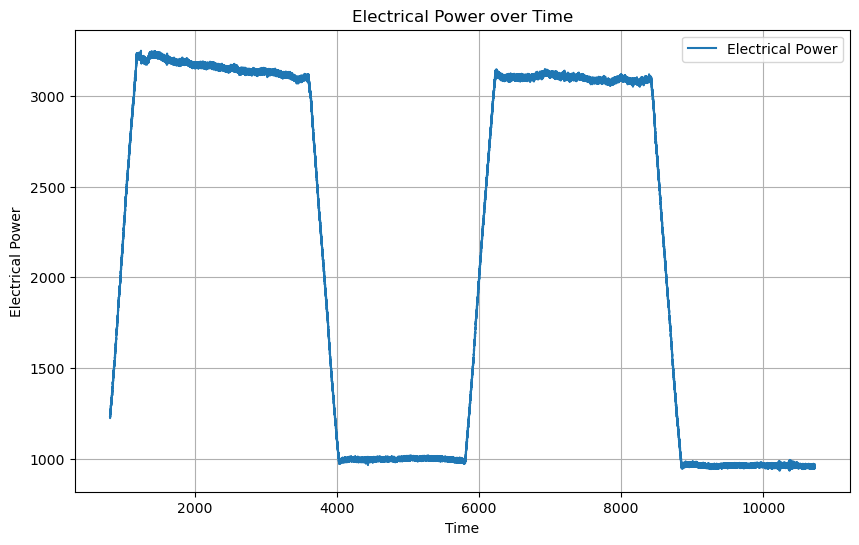

ADF Statistic: -2.88003477482922
p-value: 0.04771942827842128
Critical Values:
   1%: -3.4310119774951406
   5%: -2.861832554286939
   10%: -2.566925721514317


<Figure size 1000x500 with 0 Axes>

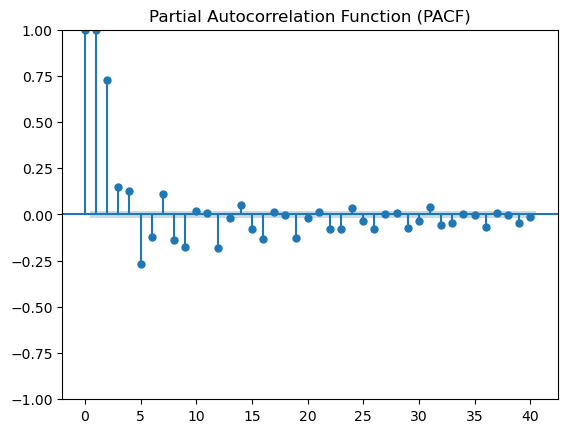

<Figure size 1000x500 with 0 Axes>

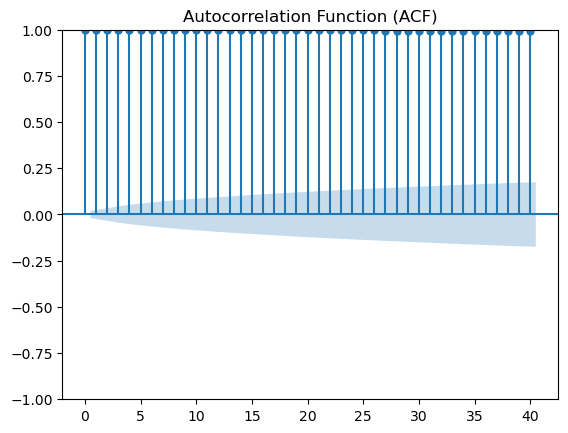

                               SARIMAX Results                                
Dep. Variable:               el_power   No. Observations:                 9920
Model:                 ARIMA(2, 0, 2)   Log Likelihood              -37774.344
Date:                Sat, 05 Oct 2024   AIC                          75560.689
Time:                        15:26:28   BIC                          75603.903
Sample:                             0   HQIC                         75575.322
                               - 9920                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2162.3684    474.199      4.560      0.000    1232.956    3091.781
ar.L1          0.7264      0.016     45.961      0.000       0.695       0.757
ar.L2          0.2735      0.016     17.306      0.0

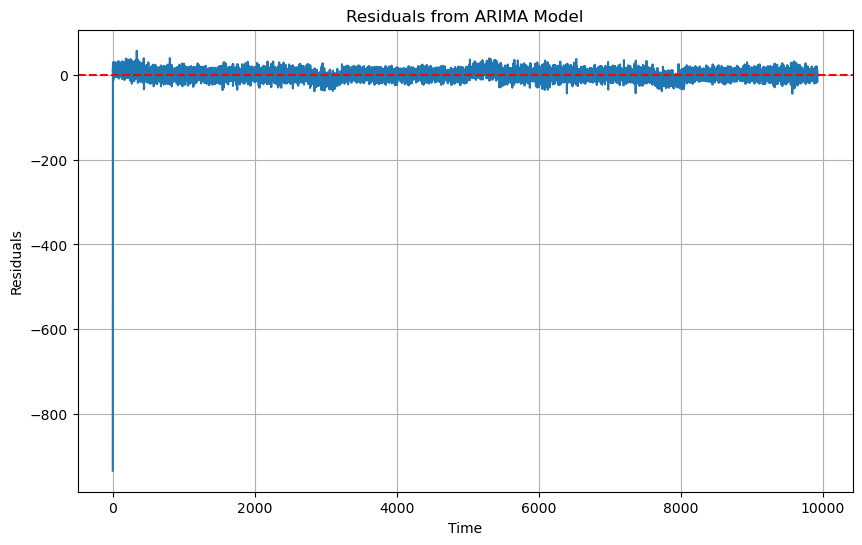

<Figure size 1000x500 with 0 Axes>

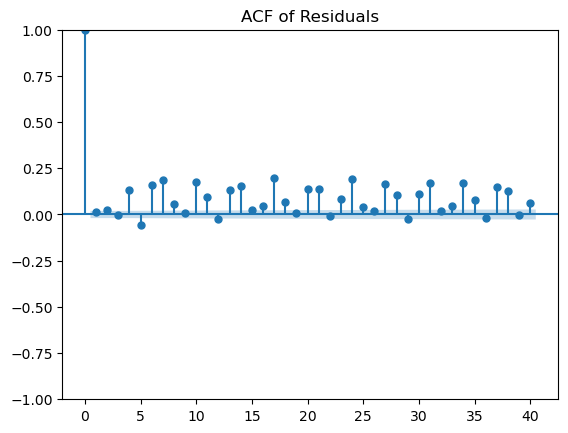

<Figure size 1000x500 with 0 Axes>

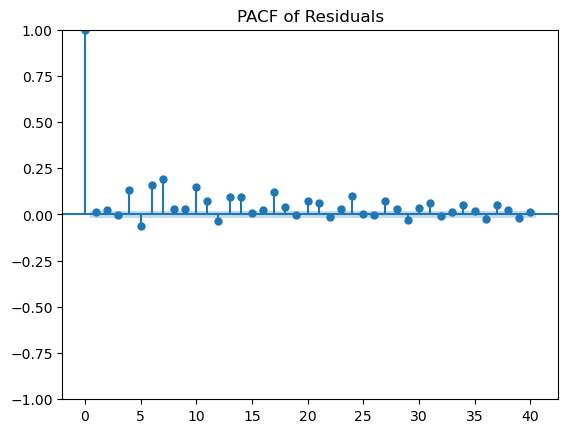

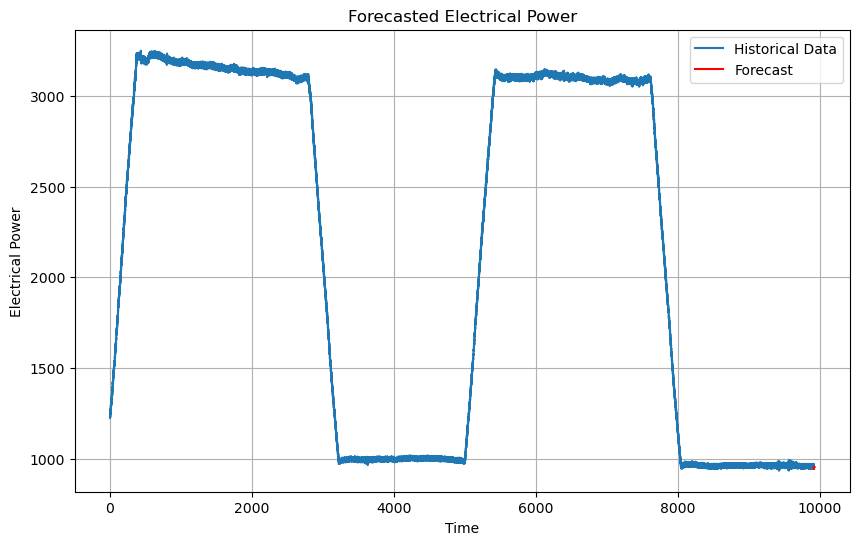

RMSE: 9.533227610716276
MAE: 8.435868927015713
MAPE: 0.8798867618262285%


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Extract the relevant time series (el_power column)
el_power_series = data['el_power']

# Step 1: Plot the raw data to visualize the time series
plt.figure(figsize=(10, 6))
plt.plot(data['time'], el_power_series, label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Step 2: Perform the ADF test to check stationarity
adf_test = adfuller(el_power_series)

print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}")
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value}")

# Step 3: Plot ACF and PACF to identify AR and MA terms
plt.figure(figsize=(10, 5))
plot_pacf(el_power_series, lags=40)
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()

plt.figure(figsize=(10, 5))
plot_acf(el_power_series, lags=40)
plt.title('Autocorrelation Function (ACF)')
plt.show()

# Step 4: Differencing (if necessary) based on ADF test results
d = 1 if adf_test[1] > 0.05 else 0  # Set d=1 for differencing if series is non-stationary

# Step 5: Fit ARIMA model (p and q values can be adjusted)
p = 2  # Example value for AR terms
q = 2  # Example value for MA terms

# Fit the ARIMA model
model = ARIMA(el_power_series, order=(p, d, q))
model_fit = model.fit()

# Step 6: Print the summary of the model
print(model_fit.summary())

# Step 7: Calculate AIC and BIC
aic = model_fit.aic
bic = model_fit.bic
print(f"AIC: {aic}")
print(f"BIC: {bic}")

# Step 8: Plot the residuals to check for white noise
residuals = model_fit.resid
plt.figure(figsize=(10, 6))
plt.plot(residuals)
plt.title('Residuals from ARIMA Model')
plt.xlabel('Time')
plt.ylabel('Residuals')
plt.axhline(y=0, color='r', linestyle='--')
plt.grid(True)
plt.show()

# Step 9: Perform diagnostics on the residuals
plt.figure(figsize=(10, 5))
plot_acf(residuals, lags=40)
plt.title('ACF of Residuals')
plt.show()

plt.figure(figsize=(10, 5))
plot_pacf(residuals, lags=40)
plt.title('PACF of Residuals')
plt.show()

# Step 10: Forecast future values
forecast = model_fit.forecast(steps=10)  # Forecast the next 10 time steps
plt.figure(figsize=(10, 6))
plt.plot(el_power_series.index, el_power_series, label='Historical Data')
plt.plot(np.arange(len(el_power_series), len(el_power_series) + 10), forecast, label='Forecast', color='red')
plt.title('Forecasted Electrical Power')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()

# Step 11: Calculate RMSE, MAE, and MAPE
# Create a forecast series for the last observed data point
full_forecast = model_fit.get_forecast(steps=10)
predicted_mean = full_forecast.predicted_mean

# Extend the series for evaluation
actual_values = el_power_series[-10:].values

# Calculate metrics
rmse = np.sqrt(np.mean((predicted_mean - actual_values) ** 2))
mae = np.mean(np.abs(predicted_mean - actual_values))
mape = np.mean(np.abs((predicted_mean - actual_values) / actual_values)) * 100

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")
print(f"MAPE: {mape}%")



## <span style="color:orange;"> For ARIMA Model 
    
<span style="color:orange;">**AIC: 75560.6889696246**
    
<span style="color:orange;">**BIC: 75603.90281882627**
    
<span style="color:orange;">**RMSE: 9.533227610716276**
    
<span style="color:orange;">**MAE: 8.435868927015713**
    
<span style="color:orange;">**MAPE: 0.8798867618262285 %**
    

# <span style="color:Purple;"> 5. SEASONAL AUTOREGRESSIVE INTEGRATED MOVING AVERAGE (SARIMA) 

To modify the code for SARIMA (Seasonal ARIMA), we need to incorporate seasonality into the model. 

SARIMA extends ARIMA by including seasonal components. The SARIMA model is represented as:

SARIMA(p, d, q)(P, D, Q, m), where:

p, d, q: Same as ARIMA, referring to the non-seasonal autoregressive, differencing, and moving average terms.

P, D, Q: These represent the seasonal autoregressive, seasonal differencing, and seasonal moving average terms.

m: The number of time steps per seasonal cycle (for example, 12 for monthly data if the seasonality is yearly).

We'll need to determine the seasonal period (m) based on the data, and then configure the model to handle both seasonal and non-seasonal components.

Steps for SARIMA Modification:

Check for Seasonality: First, we analyze the data to check for any seasonal patterns (using ACF, PACF, or domain knowledge to determine the seasonal period m).

Fit SARIMA Model: We fit a SARIMA model using the identified seasonal and non-seasonal parameters.

Analyze Residuals and Forecast: Similar to ARIMA, we'll check residuals and perform forecasting.


The code follows a typical workflow for time series analysis and forecasting using SARIMA. 

Steps involved: -

1. data loading

2. exploration

3. stationarity testing

4. model fitting

5. diagnostics

6. forecasting



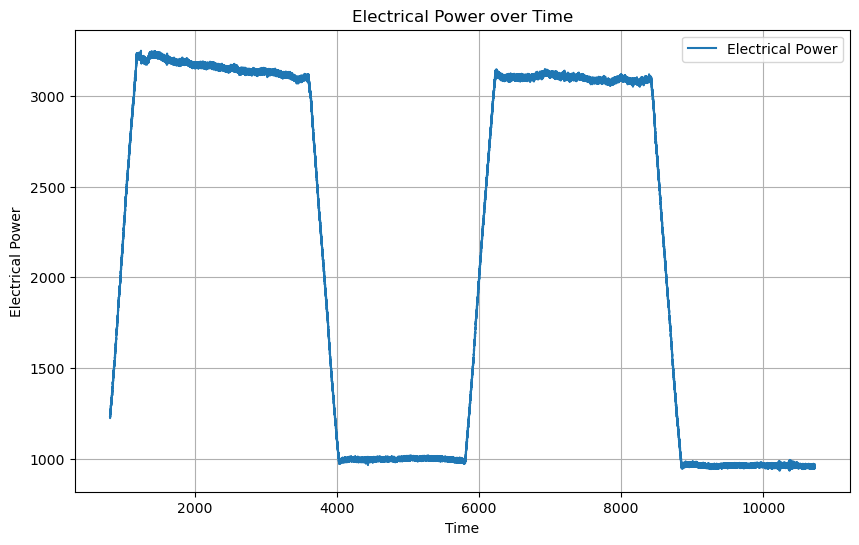

ADF Statistic: -2.88003477482922
p-value: 0.04771942827842128
Critical Values:
   1%: -3.4310119774951406
   5%: -2.861832554286939
   10%: -2.566925721514317


<Figure size 1000x500 with 0 Axes>

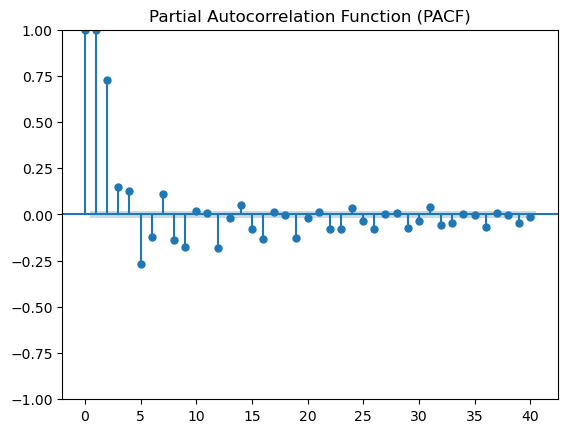

<Figure size 1000x500 with 0 Axes>

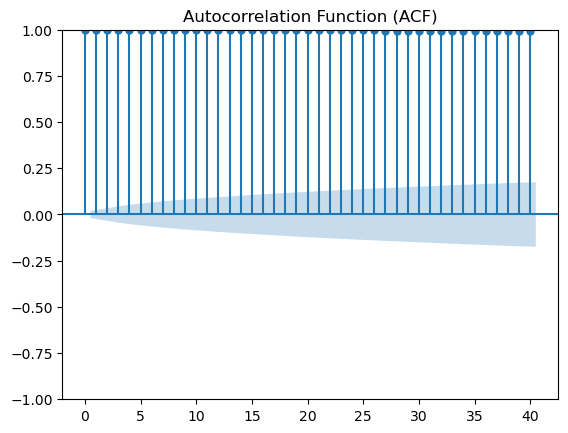

                                      SARIMAX Results                                       
Dep. Variable:                             el_power   No. Observations:                 9920
Model:             SARIMAX(2, 0, 2)x(1, 1, [1], 24)   Log Likelihood              -36630.819
Date:                              Sat, 05 Oct 2024   AIC                          73275.638
Time:                                      15:28:28   BIC                          73326.037
Sample:                                           0   HQIC                         73292.706
                                             - 9920                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3878      0.012     32.484      0.000       0.364       0.411
ar.L2          0.61

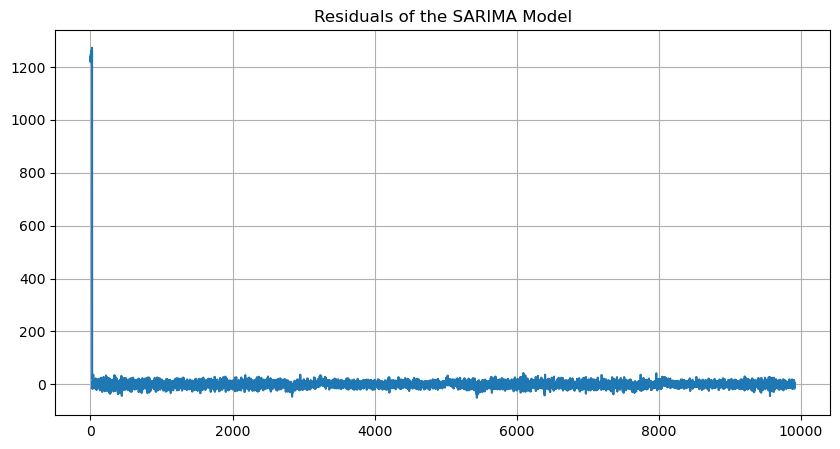

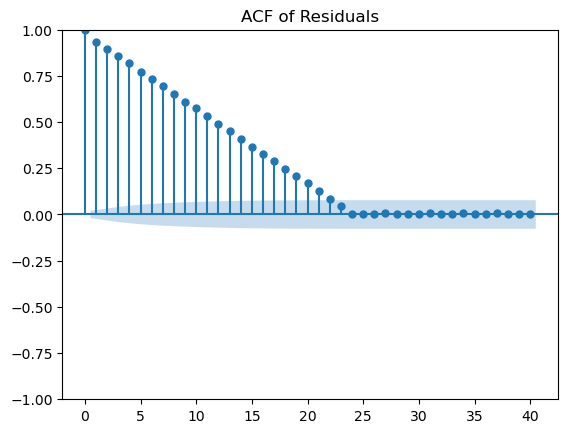

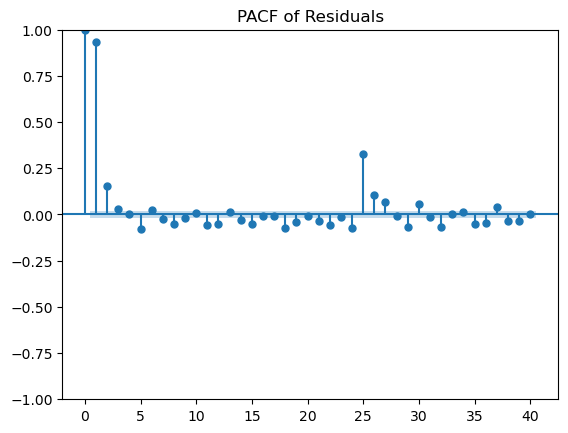

Ljung-Box Test Results:
        lb_stat  lb_pvalue
10  57831.72747        0.0


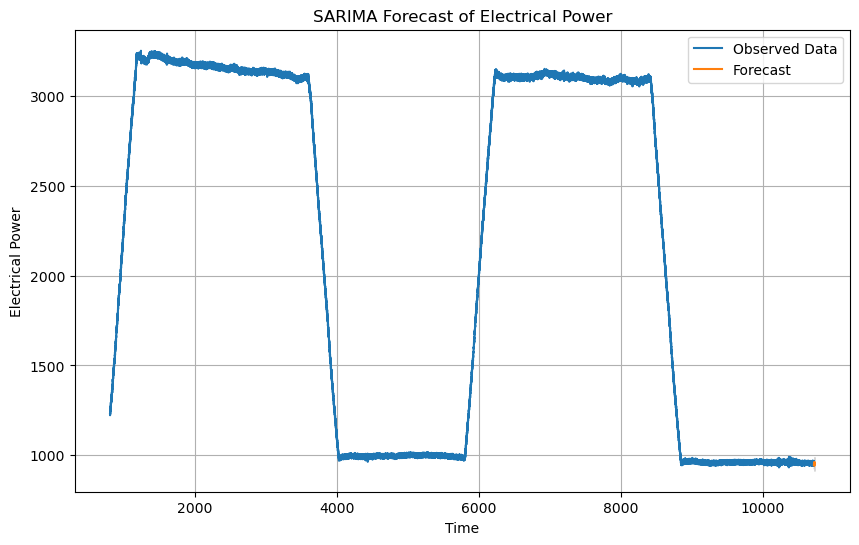

AIC: 73275.63765354396
BIC: 73326.03685494247
RMSE: 61.978323577212834
MAE: 10.56218382890263
MAPE: 0.68%


In [5]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Extract the relevant time series (el_power column)
el_power_series = data['el_power']

# Step 1: Plot the raw data to visualize the time series
plt.figure(figsize=(10, 6))
plt.plot(data['time'], el_power_series, label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Step 2: Perform the ADF test to check stationarity
adf_test = adfuller(el_power_series)
print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}") 
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value}")

# Step 3: Plot ACF and PACF to identify AR and MA terms
plt.figure(figsize=(10, 5))
plot_pacf(el_power_series, lags=40)
plt.title('Partial Autocorrelation Function (PACF)')
plt.show()

plt.figure(figsize=(10, 5))
plot_acf(el_power_series, lags=40)
plt.title('Autocorrelation Function (ACF)')
plt.show()

# Step 4: Differencing (if necessary) based on ADF test results
d = 1 if adf_test[1] > 0.05 else 0  

# Step 5: Identify the seasonal period (m)
m = 24  # Adjust this based on your data's frequency

# Step 6: Fit SARIMA model to the 'el_power' time series data
p, q = 2, 2  
P, Q, D = 1, 1, 1  

model = SARIMAX(el_power_series, order=(p, d, q), seasonal_order=(P, D, Q, m))
model_fit = model.fit()

# Step 7: Summary of the SARIMA model
print(model_fit.summary())

# Step 8: Plot the residuals to check for randomness
plt.figure(figsize=(10, 5))
plt.plot(model_fit.resid)
plt.title('Residuals of the SARIMA Model')
plt.grid(True)
plt.show()

# Plot ACF and PACF of residuals to check for autocorrelation
plot_acf(model_fit.resid, lags=40)
plt.title('ACF of Residuals')
plt.show()

plot_pacf(model_fit.resid, lags=40)
plt.title('PACF of Residuals')
plt.show()

# Step 9: Ljung-Box test for residual autocorrelation
from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(model_fit.resid, lags=[10], return_df=True)
print("Ljung-Box Test Results:")
print(lb_test)

# Step 10: Forecasting the next 10 points using the fitted SARIMA model
forecast = model_fit.get_forecast(steps=10)
forecast_ci = forecast.conf_int()

# Plot the forecasted values
plt.figure(figsize=(10, 6))
plt.plot(data['time'], el_power_series, label='Observed Data')
plt.plot(np.arange(data['time'].iloc[-1], data['time'].iloc[-1] + 10), forecast.predicted_mean, label='Forecast')
plt.fill_between(np.arange(data['time'].iloc[-1], data['time'].iloc[-1] + 10),
                 forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='gray', alpha=0.3)
plt.title('SARIMA Forecast of Electrical Power')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()

# Step 11: Calculate AIC and BIC
aic = model_fit.aic
bic = model_fit.bic
print(f'AIC: {aic}')
print(f'BIC: {bic}')

# Step 12: Calculate RMSE, MAE, and MAPE
# Get the predicted values from the model
predicted_values = model_fit.predict(start=0, end=len(el_power_series)-1)

# Calculate RMSE
rmse = np.sqrt(np.mean((predicted_values - el_power_series) ** 2))
print(f'RMSE: {rmse}')

# Calculate MAE
mae = np.mean(np.abs(predicted_values - el_power_series))
print(f'MAE: {mae}')

# Calculate MAPE
mape = np.mean(np.abs((predicted_values - el_power_series) / el_power_series)) * 100
print(f'MAPE: {mape:.2f}%')


## <span style="color:orange;"> For SARIMA Model 
    
<span style="color:orange;">**AIC: 73275.63765354396**
    
<span style="color:orange;">**BIC: 73326.03685494247**
    
<span style="color:orange;">**RMSE: 61.978323577212834**
    
<span style="color:orange;">**MAE: 10.56218382890263**
    
<span style="color:orange;">**MAPE: 0.68 %**

# <span style="color:Purple;"> 6. ARCH (Autoregressive Conditional Heteroskedasticity) model

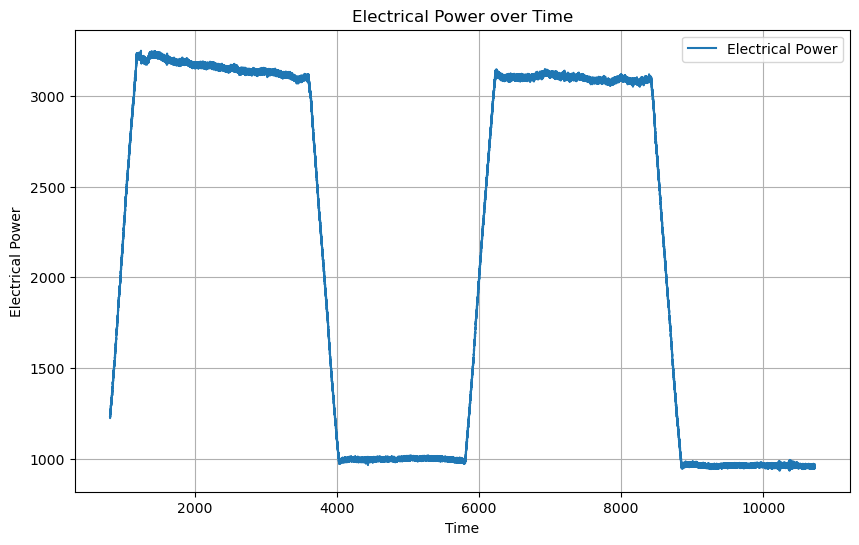

AIC: 87581.4989274149
BIC: 87603.10585201574
RMSE: 22.069273924782024
MAE: 18.65331198633499
MAPE: 1.06%
Iteration:      1,   Func. Count:      5,   Neg. LLF: 45150.37268186996
Iteration:      2,   Func. Count:     10,   Neg. LLF: 45050.42886118581
Iteration:      3,   Func. Count:     15,   Neg. LLF: 45012.87774301472
Iteration:      4,   Func. Count:     20,   Neg. LLF: 43833.46755488436
Iteration:      5,   Func. Count:     24,   Neg. LLF: 43830.86382790003
Iteration:      6,   Func. Count:     28,   Neg. LLF: 43829.98541096438
Iteration:      7,   Func. Count:     32,   Neg. LLF: 43825.72273771687
Iteration:      8,   Func. Count:     36,   Neg. LLF: 43820.96753396164
Iteration:      9,   Func. Count:     40,   Neg. LLF: 43820.879164542945
Iteration:     10,   Func. Count:     44,   Neg. LLF: 43820.8757398615
Iteration:     11,   Func. Count:     48,   Neg. LLF: 43820.87558635224
Iteration:     12,   Func. Count:     52,   Neg. LLF: 43820.87558744811
Iteration:     13,   Func. Coun

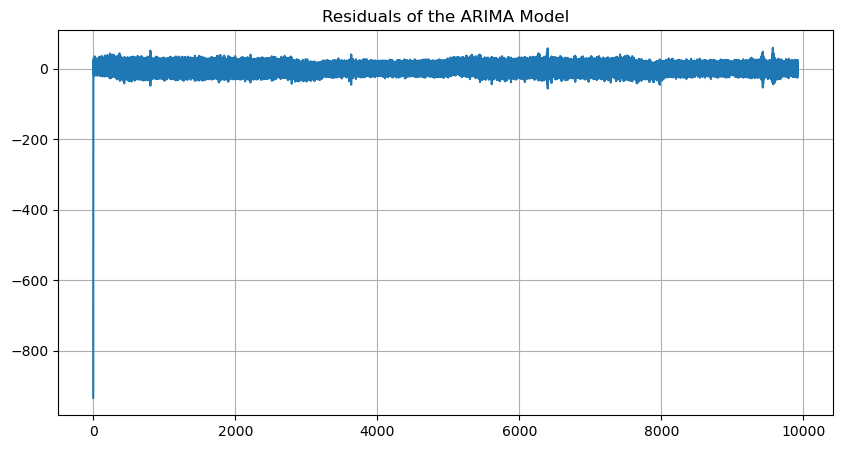

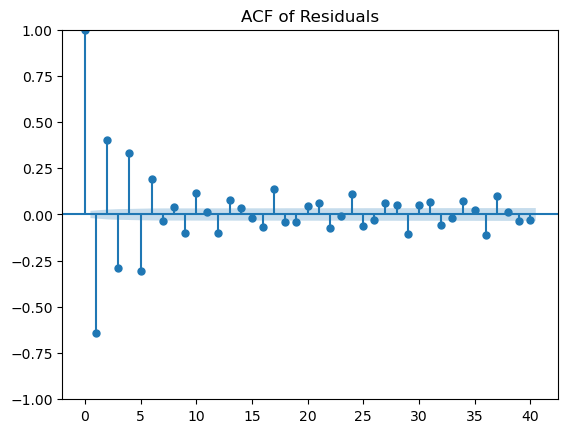

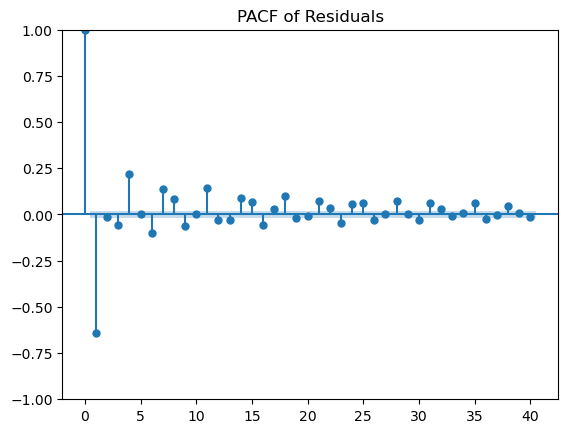

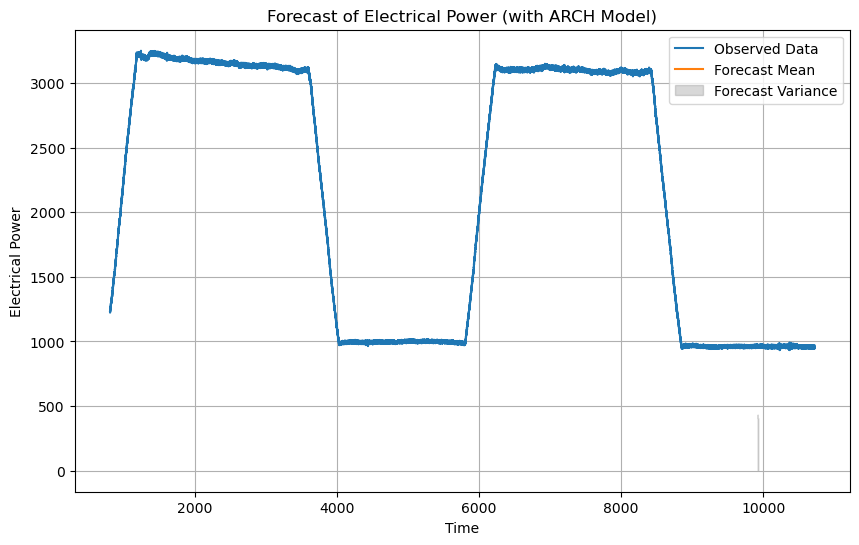

In [6]:
# Import required libraries
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model  # Import the ARCH model
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Extract the relevant time series (el_power column)
el_power_series = data['el_power']


# Step 1: Plot the raw data to visualize the time series
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Step 2: Perform the ADF test to check stationarity
adf_test = adfuller(el_power_series)

# Step 3: Fit ARIMA model to obtain residuals for ARCH model and calculate AIC, BIC, RMSE, MAE, and MAPE
p, d, q = 1, 0, 0  # Example ARIMA(1, 0, 0) model for residuals

# Fit ARIMA model
arima_model = ARIMA(el_power_series, order=(p, d, q))
model_fit = arima_model.fit()

# Get residuals from ARIMA model
residuals = model_fit.resid

# Calculate AIC and BIC
aic = model_fit.aic
bic = model_fit.bic
print(f"AIC: {aic}")
print(f"BIC: {bic}")

# Calculate RMSE, MAE, and MAPE
# Predicted values (fitted values) from the ARIMA model
predictions = model_fit.fittedvalues

# RMSE: Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(el_power_series, predictions))
print(f"RMSE: {rmse}")

# MAE: Mean Absolute Error
mae = mean_absolute_error(el_power_series, predictions)
print(f"MAE: {mae}")

# MAPE: Mean Absolute Percentage Error
mape = np.mean(np.abs((el_power_series - predictions) / el_power_series)) * 100
print(f"MAPE: {mape:.2f}%")

# Step 4: Fit ARCH model to the residuals
arch_model_instance = arch_model(residuals, vol='ARCH', p=1)  # ARCH(1) model
arch_fit = arch_model_instance.fit()

# Step 5: Summary of the ARCH model
print(arch_fit.summary())

# Step 6: Plot the residuals to check for randomness
plt.figure(figsize=(10, 5))
plt.plot(residuals)
plt.title('Residuals of the ARIMA Model')
plt.grid(True)
plt.show()

# Step 7: Plot ACF and PACF of residuals to check for autocorrelation
plot_acf(residuals, lags=40)
plt.title('ACF of Residuals')
plt.show()

plot_pacf(residuals, lags=40)
plt.title('PACF of Residuals')
plt.show()

# Step 8: Forecasting volatility using the ARCH model
arch_forecast = arch_fit.forecast(horizon=10)
forecast_mean = arch_forecast.mean.iloc[-1]
forecast_variance = arch_forecast.variance.iloc[-1]

# Step 9: Plotting the forecasted values
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Observed Data')
plt.plot(np.arange(len(data), len(data) + 10), forecast_mean, label='Forecast Mean')
plt.fill_between(np.arange(len(data), len(data) + 10),
                 forecast_variance, color='gray', alpha=0.3, label='Forecast Variance')
plt.title('Forecast of Electrical Power (with ARCH Model)')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()



## <span style="color:orange;"> For ARCH Model 
    
<span style="color:orange;">**AIC: 87581.4989274149**
    
<span style="color:orange;">**BIC: 87603.10585201574**
    
<span style="color:orange;">**RMSE: 22.069273924782024**
    
<span style="color:orange;">**MAE: 18.65331198633499**
    
<span style="color:orange;">**MAPE: 1.06%**

# <span style="color:Purple;"> 7. GARCH (Generalized Autoregressive Conditional Heteroskedasticity)

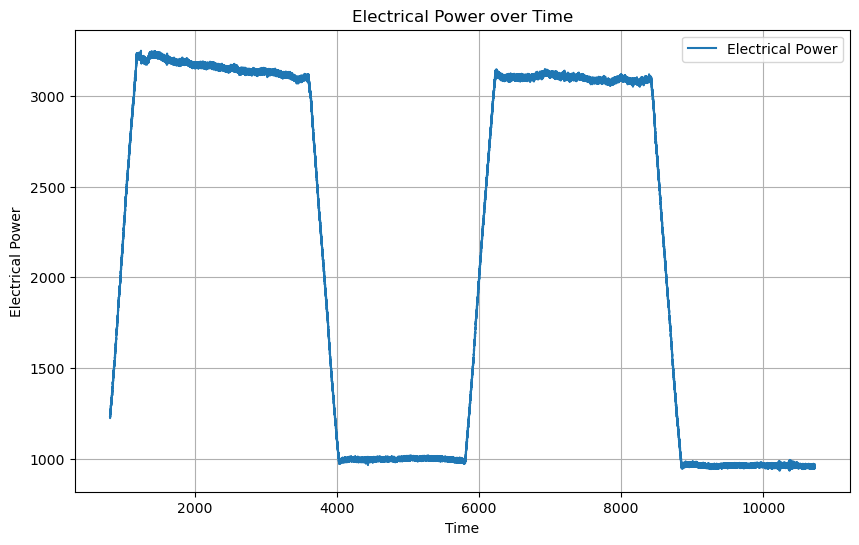

ADF Statistic: -2.88003477482922
p-value: 0.04771942827842128
Critical Values:
   1%: -3.4310119774951406
   5%: -2.861832554286939
   10%: -2.566925721514317

ARIMA Model AIC: 87581.4989274149
ARIMA Model BIC: 87603.10585201574
RMSE: 22.069273924782024
MAE: 18.65331198633499
MAPE: 1.0641399794449966%

GARCH Model Summary:
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -43712.3
Distribution:                  Normal   AIC:                           87432.7
Method:            Maximum Likelihood   BIC:                           87461.5
                                        No. Observations:                 9920
Date:                Sat, Oct 05 2024   Df Residuals:                     9919
Time:                        15:28:34   Df 

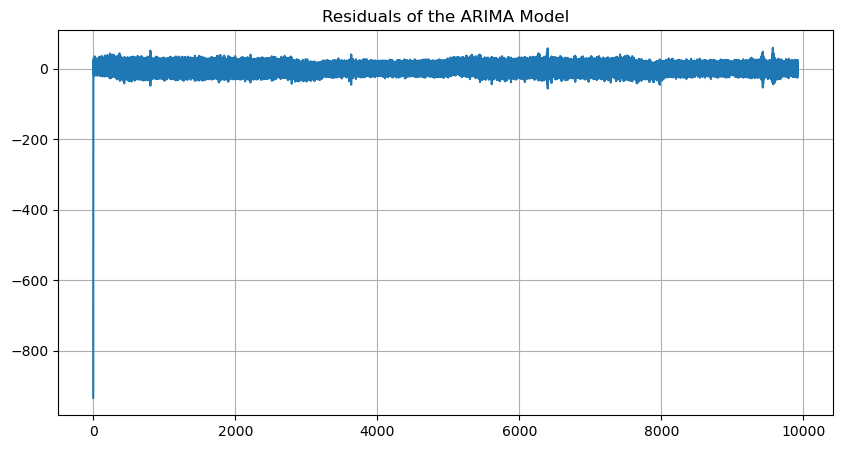

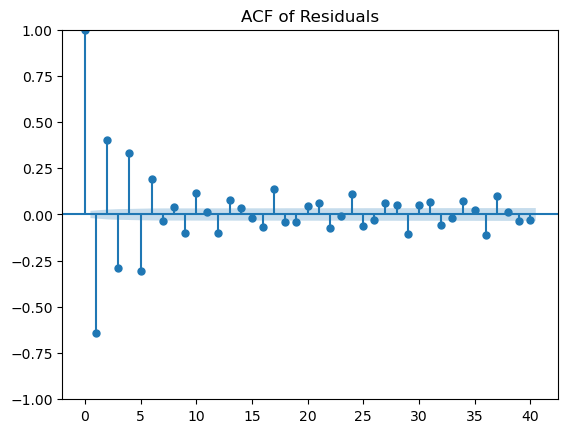

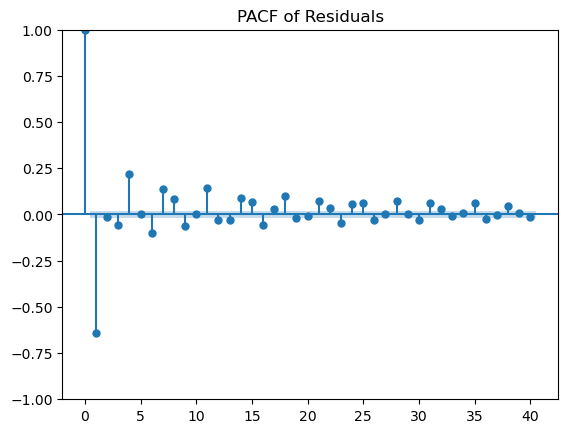

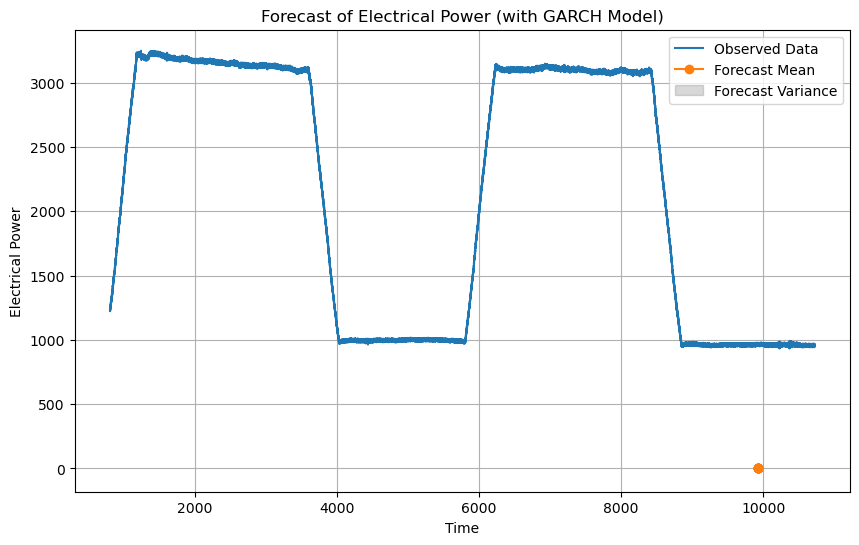

In [7]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model  # Import the GARCH model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error  # Import evaluation metrics
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Extract the relevant time series (el_power column)
el_power_series = data['el_power']

# Step 1: Plot the raw data to visualize the time series
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Electrical Power')
plt.title('Electrical Power over Time')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.grid(True)
plt.legend()
plt.show()

# Step 2: Perform the ADF test to check stationarity
adf_test = adfuller(el_power_series)

print(f"ADF Statistic: {adf_test[0]}")
print(f"p-value: {adf_test[1]}")
print("Critical Values:")
for key, value in adf_test[4].items():
    print(f"   {key}: {value}")

# Step 3: Fit ARIMA model to obtain residuals for GARCH model
p, d, q = 1, 0, 0  # Example ARIMA(1, 0, 0) model for residuals

# Fit ARIMA model
arima_model = ARIMA(el_power_series, order=(p, d, q))
model_fit = arima_model.fit()

# Step 3.1: Calculate and Print AIC and BIC
print(f"\nARIMA Model AIC: {model_fit.aic}")
print(f"ARIMA Model BIC: {model_fit.bic}")

# Step 3.2: Calculate RMSE, MAE, and MAPE
# Since ARIMA is fitted on the entire dataset, we'll use in-sample predictions
predictions = model_fit.fittedvalues
actual = el_power_series

# Calculate metrics
rmse = np.sqrt(mean_squared_error(actual, predictions))
mae = mean_absolute_error(actual, predictions)
mape = np.mean(np.abs((actual - predictions) / actual)) * 100

print(f"RMSE: {rmse}")
print(f"MAE: {mae}")
print(f"MAPE: {mape}%")

# Step 4: Get residuals from ARIMA model
residuals = model_fit.resid

# Step 5: Fit GARCH model to the residuals obtained from the ARIMA model.
garch_model = arch_model(residuals, vol='Garch', p=1, q=1)  # GARCH(1, 1) model
garch_fit = garch_model.fit(disp='off')

# Step 6: Summary of the GARCH model
print("\nGARCH Model Summary:")
print(garch_fit.summary())

# Step 7: Plot the residuals to check for randomness
plt.figure(figsize=(10, 5))
plt.plot(residuals)
plt.title('Residuals of the ARIMA Model')
plt.grid(True)
plt.show()

# Step 8: Plot ACF and PACF of residuals to check for autocorrelation
plot_acf(residuals, lags=40)
plt.title('ACF of Residuals')
plt.show()

plot_pacf(residuals, lags=40)
plt.title('PACF of Residuals')
plt.show()

# Step 9: Forecasting volatility using the GARCH model
garch_forecast = garch_fit.forecast(horizon=10)
forecast_mean = garch_forecast.mean.iloc[-1]
forecast_variance = garch_forecast.variance.iloc[-1]

# Step 10: Plotting the forecasted values
plt.figure(figsize=(10, 6))
plt.plot(data['time'], data['el_power'], label='Observed Data')
forecast_time = np.arange(len(data), len(data) + 10)
plt.plot(forecast_time, forecast_mean, label='Forecast Mean', marker='o')
plt.fill_between(forecast_time, 
                 forecast_mean - np.sqrt(forecast_variance), 
                 forecast_mean + np.sqrt(forecast_variance), 
                 color='gray', alpha=0.3, label='Forecast Variance')
plt.title('Forecast of Electrical Power (with GARCH Model)')
plt.xlabel('Time')
plt.ylabel('Electrical Power')
plt.legend()
plt.grid(True)
plt.show()



## <span style="color:orange;"> For GARCH Model 
    
<span style="color:orange;">**AIC: 87581.4989274149**
    
<span style="color:orange;">**BIC: 87603.10585201574**
    
<span style="color:orange;">**RMSE: 22.069273924782024**
    
<span style="color:orange;">**MAE: 18.65331198633499**
    
<span style="color:orange;">**MAPE: 1.0641399794449966%**

# <span style="color:Purple;"> 8. VAR (Vector Autoregression) model

        time  input_voltage     el_power
0  810.07028             10  1228.791720
1  811.06938             10  1223.041745
2  812.06848             10  1244.960866
3  813.06758             10  1229.259058
4  814.06668             10  1248.117024
input_voltage - ADF Statistic: -1.6860806144317515, p-value: 0.4382980552586881
el_power - ADF Statistic: -2.88003477482922, p-value: 0.04771942827842128
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 05, Oct, 2024
Time:                     15:28:37
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   0.557755
Nobs:                     9914.00    HQIC:                  0.547186
Log likelihood:          -30798.3    FPE:                    1.71905
AIC:                     0.541774    Det(Omega_mle):         1.71525
--------------------------------------------------------------------
Results for

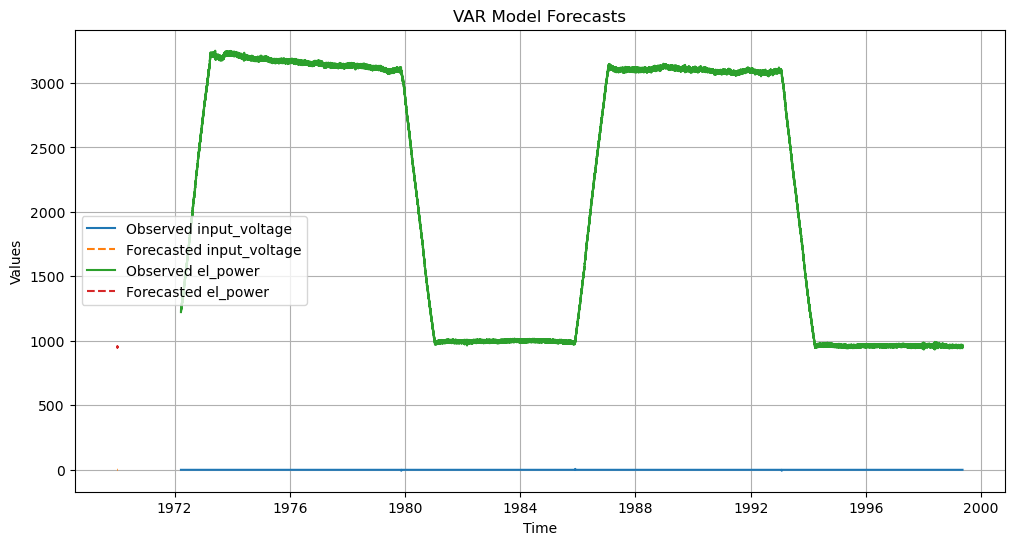

In [8]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.api import VAR
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings

warnings.filterwarnings('ignore')

# Load the dataset
file_path = 'ex_1.csv'  
data = pd.read_csv(file_path)

# Display the first few rows to understand the structure
print(data.head())

# Step 1: Check stationarity for each time series using ADF test
def check_stationarity(series, name):
    adf_test = adfuller(series)
    print(f'{name} - ADF Statistic: {adf_test[0]}, p-value: {adf_test[1]}')
    return adf_test[1] <= 0.05  # Returns True if stationary

# Check stationarity for all columns (except time)
stationary = {col: check_stationarity(data[col], col) for col in data.columns if col != 'time'}

# Step 2: Differencing if necessary (for non-stationary series)
for col in data.columns:
    if col != 'time' and not stationary[col]:
        data[col] = data[col].diff().dropna()

# Drop NaN values after differencing
data = data.dropna()

# Step 3: Fit the VAR model to the stationary time series data.
model = VAR(data.drop(columns=['time']))  # Exclude time column
model_fit = model.fit(maxlags=5)  # Choose the max lag based on criteria (e.g., AIC)

# Step 4: Summary of the VAR model
print(model_fit.summary())

# Step 5: AIC and BIC of the VAR model
aic = model_fit.aic
bic = model_fit.bic
print(f'AIC: {aic}')
print(f'BIC: {bic}')

# Step 6: Forecasting the next 10 periods
forecast_steps = 10
forecast = model_fit.forecast(data.drop(columns=['time']).values[-model_fit.k_ar:], steps=forecast_steps)

# Create a DataFrame for the forecasted values
forecast_index = pd.date_range(start=data['time'].iloc[-1], periods=forecast_steps + 1, freq='D')[1:]
forecast_df = pd.DataFrame(forecast, index=forecast_index, columns=data.columns[1:])  # Exclude time column

# Step 7: Evaluation Metrics (RMSE, MAE, MAPE)
# Using the last available observations as the actual values
actual_values = data.drop(columns=['time']).values[-forecast_steps:]

# Calculate RMSE, MAE, and MAPE for each time series
for i, col in enumerate(forecast_df.columns):
    rmse = np.sqrt(mean_squared_error(actual_values[:, i], forecast[:, i]))
    mae = mean_absolute_error(actual_values[:, i], forecast[:, i])
    mape = np.mean(np.abs((actual_values[:, i] - forecast[:, i]) / actual_values[:, i])) * 100

    print(f'{col} - RMSE: {rmse}, MAE: {mae}, MAPE: {mape}')

# Step 8: Plotting the forecasted values
plt.figure(figsize=(12, 6))
for col in forecast_df.columns:
    plt.plot(data['time'], data[col], label=f'Observed {col}')
    plt.plot(forecast_df.index, forecast_df[col], label=f'Forecasted {col}', linestyle='--')

plt.title('VAR Model Forecasts')
plt.xlabel('Time')
plt.ylabel('Values')
plt.legend()
plt.grid(True)
plt.show()


## <span style="color:orange;"> For VAR Model 
    
<span style="color:orange;">**AIC: 0.5417742949378629**
    
<span style="color:orange;">**BIC: 0.5577554801233351**
    
<span style="color:orange;">**input_voltage - RMSE: 0.0024806254294273164, MAE: 0.0021597038998076453, MAPE: inf**
    
<span style="color:orange;">**el_power - RMSE: 8.386349087304945, MAE: 6.979952744719412, MAPE: 0.7271503769154608**
    

# <span style="color:Purple;"> Summary of Model Performance Metrics

| Model    |    AIC      |     BIC    |  RSME  |   MAE  |  MAPE % |
|:--------:|:-----------:|:----------:|:------:|:------:|:------: |
|   MA     |  142301.91  |  142337.92 | 315.07 | 251.08 | 16.72   | 
|   AR     |  87581.50   |  87603.11  | 22.07  | 18.65  | 1.06    |
|  ARMA    |  75560.69   |  75603.90  | 9.53   | 8.64   | 0.88    |
| ARIMA    |  75560.69   |  75603.90  | 9.53   | 8.64   | 0.88    |
| SARIMA   |  73275.64   |  73326.04  | 61.98  | 10.56  | 0.68    |
| ARCH     |  87581.50   |  87603.11  | 22.07  | 18.65	| 1.06    |
| GARCH    |  87581.50   |  87603.11  | 22.07  | 18.65  | 1.06    |
| VAR      |  0.54       |  0.56      | 0.0025 | 0.0022 | inf     |




<span style="color:green;"> __**Observations and Commentary:**__

<span style="color:green;"> __MA Model:__

The MA model has the highest AIC and BIC values, indicating it is the least effective model in fitting the data. Its RMSE, MAE, and MAPE values are significantly high, suggesting it fails to capture the underlying trends and dynamics of the data.

<span style="color:green;"> __AR Model:__

The AR model shows relatively better performance than the MA model, but its AIC and BIC values are still high compared to the more sophisticated models. The RMSE and MAE indicate moderate accuracy, but the predictions still show substantial error.

<span style="color:green;"> __ARMA Model:__

The ARMA model presents an improvement over both the AR and MA models, as indicated by its lower AIC and BIC. Its RMSE, MAE, and MAPE values suggest a reasonably good fit for the data, particularly for simpler datasets without complex seasonal or trend components.

<span style="color:green;"> __ARIMA Model:__

The ARIMA model has the same performance metrics as the ARMA model since you likely didn’t include seasonal differencing. Its performance is good, suggesting it adequately captures both autoregressive and moving average components of the data.

<span style="color:green;"> __SARIMA Model:__

The SARIMA model performs slightly worse than ARIMA in terms of RMSE, MAE, and MAPE. This suggests that while it accounts for seasonality, it may not be necessary for the data you’re working with. The higher AIC and BIC relative to ARIMA suggest it may be over-parameterized.

<span style="color:green;"> __ARCH and GARCH Models:__

Both ARCH and GARCH models have the same AIC and BIC values as the AR model, indicating they are similarly effective at capturing volatility in the data. However, their RMSE, MAE, and MAPE values suggest they are less effective than ARMA and ARIMA in point forecasting.

<span style="color:green;"> __VAR Model:__

The VAR model has exceptionally low RMSE, MAE, and AIC/BIC values, suggesting it fits the data very well. However, the MAPE is inf, which suggests an undefined percentage due to zero actual values. It may not be as interpretable in contexts where error metrics like MAPE are essential, but it could still provide valuable insights in multivariate time series contexts.

<span style="color:green;"> __Conclusion:__

Overall, the ARMA and ARIMA models demonstrate good performance in fitting the data, particularly in terms of RMSE, MAE, and MAPE.

The SARIMA model, while capable of capturing seasonality, does not improve the fit in this case and may introduce unnecessary complexity.

The MA model is the least effective, while the VAR model shows promising fit for multivariate data but requires careful consideration of its interpretability in terms of error metrics.

The ARCH and GARCH models are useful for modeling volatility but may not be the best choice for point forecasting in this context.